# Can a VAE generate extreme Irish wind storms? A learning notebook

This notebook explains the talk's pipeline from the ground up: **the maths, the choices, and what the results
mean**. Every figure is built from code you can change. It runs in about a minute: it loads the trained models
from `talk/results/models/` instead of retraining (`python talk/tune.py`, `final.py`, `evaluate.py` rebuild
everything, ~1 hour).

**How to use it.** Each section ends in a 🤔 *predict first* box: write down your guess *before* opening the
answer. The ✍️ *exercises* are for you to code; hints are given, solutions are not.

| | |
|---|---|
| **Question** | Oliveira et al. (2021) generate more extreme fields from a VAE by sampling the latent with a wider spread, $z \sim \mathcal N(0, \sigma^2 I)$, $\sigma > 1$. Do the generated tails match the real ones? |
| **Hypothesis** | σ-scaling makes fields windier, but **underestimates extremes**: MSE blurs peaks, and a Gaussian latent pushed through a smooth decoder has light tails. |
| **Two models** | Identical VAEs. **(a)** trained on z-scored gusts (the baseline); **(b)** trained on gusts whose per-pixel distribution is mapped to N(0, 1) with an **extreme-value (GPD) tail**. |
| **Data** | ERA5 daily max 10 m gust, 32×32 box around Ireland, train 1985–2014, val 2015–19 (all tuning), test 2020–24 (final numbers). |

Contents: 1 data · 2 VAE maths · 3 why MSE blurs peaks · 4 why Gaussian latents give light tails ·
5 σ-scaling · 6 EVT margins · 7 tuning · 8 results · 9 visualisation choices · 10 limitations · 11 exercises

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Image, display

TALK = Path.cwd() if (Path.cwd() / "wind.py").exists() else Path.cwd() / "talk"
sys.path.insert(0, str(TALK))
import wind as W, plots as P
P.style()

data, lat, lon = W.load("gust")
mask = W.ireland_mask(lat, lon)
train, test = data["train"][0], data["test"][0]
models = {n: W.load_model(TALK / "results" / "models" / f"{n}_s0.pt") for n in ["zscore", "evt"]}
summary = json.loads((TALK / "results" / "summary.json").read_text())
print({n: models[n][2] for n in models}, "| device:", W.DEVICE)

{'zscore': {'latent_dim': 8, 'beta': 1.0, 'seed': 0}, 'evt': {'latent_dim': 8, 'beta': 1.0, 'seed': 0}} | device: cuda


## 1. The data: a skewed, bounded-below variable with a long upper tail

Daily-maximum gust at one location is always positive and **right-skewed**: most days are 10–20 m/s, a few are
40+. The extremes we care about are a tiny fraction of the data, so any loss that averages over all pixels and
days will mostly be about ordinary days.

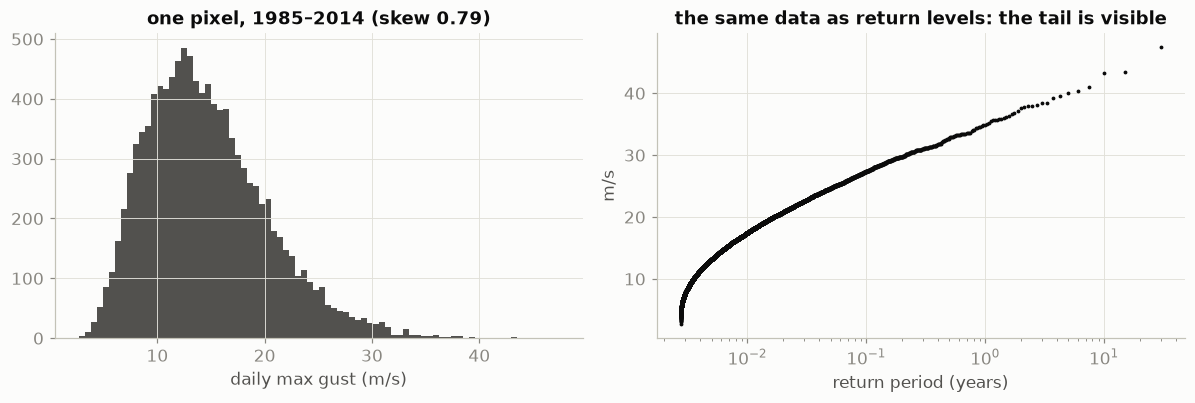

In [2]:
p = int(np.argmax(train.reshape(len(train), -1).max(0) * mask.ravel()))   # windiest land pixel (north coast)
x = train.reshape(len(train), -1)[:, p]
skew = ((x - x.mean())**3).mean() / x.std()**3
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.hist(x, bins=80, color=P.INK2); a.set_xlabel("daily max gust (m/s)"); a.set_title(f"one pixel, 1985–2014 (skew {skew:.2f})")
v, T = P.exceedance(x)
b.plot(T, v, ".", ms=3, color=P.INK); b.set_xscale("log"); b.set_xlabel("return period (years)")
b.set_ylabel("m/s"); b.set_title("the same data as return levels: the tail is visible")
plt.tight_layout()

The right panel is the most useful way to look at extremes: sort the values, and plot each against **how
often** a value that high occurs. A value exceeded on a fraction $p$ of days has return period
$T = 1/(365.25\,p)$ years. The histogram hides the tail in a few invisible bars; the return-level plot spreads
it over half the axis.

> **🤔 Predict first:** The 30-year record gives return periods up to ~30 years. What's the problem with estimating the 100-year gust from this data alone?
>
> <details><summary>Answer (open after you've guessed)</summary>
>
> There are no observations beyond ~30 years, so the empirical curve simply stops. Estimating beyond it needs a *model of the tail*: that is exactly what the Generalised Pareto distribution in Section 6 provides, and what a generative model is implicitly claiming to do when it produces storms worse than any in the training data.
>
> </details>

## 2. The VAE, in maths and in code

**Generative story.** Draw a code $z \sim p(z) = \mathcal N(0, I_d)$, then a map $x \sim p_\theta(x \mid z)$,
where the decoder network $f_\theta$ gives the mean: $p_\theta(x\mid z) = \mathcal N(f_\theta(z), I)$.

**Training** maximises the evidence lower bound (ELBO) for each training map $x$:

$$
\log p_\theta(x) \;\ge\; \underbrace{\mathbb E_{q_\phi(z\mid x)}\big[\log p_\theta(x\mid z)\big]}_{\text{reconstruction}}
\;-\; \underbrace{\mathrm{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big)}_{\text{keep codes near the prior}}
$$

with the encoder $q_\phi(z\mid x) = \mathcal N(\mu_\phi(x), \operatorname{diag}\sigma^2_\phi(x))$.

**Where MSE comes from.** For a unit-variance Gaussian decoder,
$-\log p_\theta(x\mid z) = \tfrac12\lVert x - f_\theta(z)\rVert^2 + \text{const}$. So *sum of squared errors over
the 1024 pixels* is the negative log-likelihood (up to a factor ½ that is absorbed into β). Choosing MSE **is**
choosing a Gaussian, symmetric, constant-variance noise model, the same at a calm inland pixel as in a storm.

**The KL term in closed form** (Kingma & Welling 2013, App. B), per latent dimension:

$$
\mathrm{KL}\big(\mathcal N(\mu, \sigma^2)\,\|\,\mathcal N(0,1)\big) = -\tfrac12\big(1 + \log\sigma^2 - \mu^2 - \sigma^2\big)
$$

**Reparameterisation.** To backpropagate through the sampling, write $z = \mu + \sigma\odot\varepsilon$,
$\varepsilon\sim\mathcal N(0, I)$: the randomness moves into $\varepsilon$, which has no parameters.

**β.** We minimise $\text{recon} + \beta\cdot\text{KL}$. β = 1 is the ELBO; β > 1 pulls codes harder towards the
prior (smoother, more "sample-able" latent space, blurrier reconstructions); β < 1 the opposite.
Here is the code that does all of this (from `talk/wind.py`):

In [3]:
import inspect
print(inspect.getsource(W.vae_loss))
print(inspect.getsource(W.VAE.forward))
m = models["zscore"][0]
print(f"parameters: {sum(p.numel() for p in m.parameters()):,}; latent size d = {m.latent_dim}")

def vae_loss(x, x_hat, mu, logvar, beta):
    """Sum over pixels / latent dims, mean over the batch: beta = 1 is the (unit-variance Gaussian) ELBO."""
    n = x.shape[0]
    recon = ((x_hat - x) ** 2).sum() / n
    kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum() / n
    return recon + beta * kl, recon, kl

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decode(z), mu, logvar

parameters: 380,241; latent size d = 8


> **🤔 Predict first:** The loss sums over pixels but averages over the batch. What would go wrong if it averaged over the 1024 pixels too, keeping β = 1?
>
> <details><summary>Answer (open after you've guessed)</summary>
>
> The reconstruction term would shrink by a factor 1024 while KL stays the same size, so β = 1 would really act like β ≈ 1024 in ELBO units. The KL would dominate, the encoder would ignore the input (posterior collapse) and every reconstruction would look like the average map.
>
> </details>

## 3. Why MSE blurs the peaks (the first half of the hypothesis)

The prediction that minimises expected squared error is the **conditional mean**:
$\arg\min_{\hat x}\mathbb E[(x - \hat x)^2] = \mathbb E[x]$. When the model is unsure *exactly where* a storm's
strongest band sits (a few pixels either way), the MSE-optimal map is the **average over the possible
positions**, and averaging shifted peaks lowers and widens the peak. The demo below takes the windiest real
day and averages it over small shifts: it is what an uncertain MSE model is pushed towards.

{0: np.float32(0.0), 1: np.float32(-1.31), 2: np.float32(-1.85), 3: np.float32(-2.32), 4: np.float32(-2.73), 6: np.float32(-3.54)} | measured VAE bias: -1.69


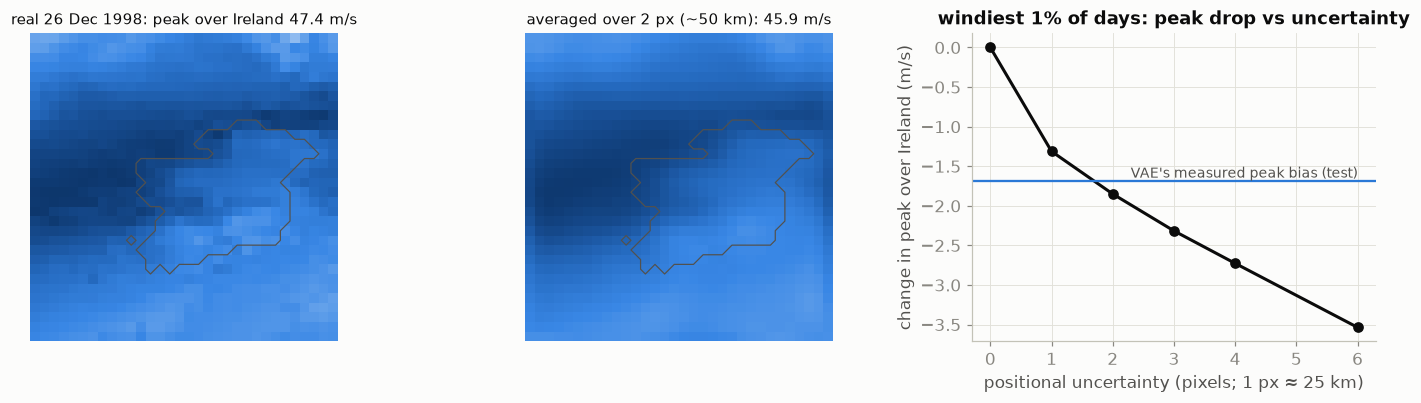

In [4]:
def blur(field, radius):
    # average a map over all shifts within `radius` pixels: what an MSE model unsure of position predicts
    # (np.roll wraps at the box edges; fine here because the Ireland mask is well inside the box)
    sh = [(a, b) for a in range(-radius, radius + 1) for b in range(-radius, radius + 1) if a*a + b*b <= radius*radius]
    return np.mean([np.roll(field, s_, axis=(0, 1)) for s_ in sh], axis=0)

top = np.argsort(W.domain_max(train, mask))[::-1][:110]          # windiest 1% of training days
radii = [0, 1, 2, 3, 4, 6]
drop = [np.mean([blur(train[i], R)[mask].max() - train[i][mask].max() for i in top]) for R in radii]
measured = summary["reconstruction_test"]["zscore"]["peak_bias_top1pct_ms_mean"]

i = top[0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
P.wind_map(axes[0], train[i], lat, lon, vmin=10, vmax=55, mask=mask, peak=False,
           title=f"real {pd.to_datetime(data['train'][1][i]):%d %b %Y}: peak over Ireland {train[i][mask].max():.1f} m/s")
P.wind_map(axes[1], blur(train[i], 2), lat, lon, vmin=10, vmax=55, mask=mask, peak=False,
           title=f"averaged over 2 px (~50 km): {blur(train[i], 2)[mask].max():.1f} m/s")
axes[2].plot(radii, drop, "o-", color=P.INK)
axes[2].axhline(measured, color=P.COLORS["zscore"], lw=1.5)
axes[2].text(radii[-1], measured, "VAE's measured peak bias (test)", ha="right", va="bottom", fontsize=9, color=P.INK2)
axes[2].set_xlabel("positional uncertainty (pixels; 1 px ≈ 25 km)"); axes[2].set_ylabel("change in peak over Ireland (m/s)")
axes[2].set_title("windiest 1% of days: peak drop vs uncertainty")
plt.tight_layout()
print(dict(zip(radii, np.round(drop, 2))), "| measured VAE bias:", round(measured, 2))

The mean wind barely changes; the **peak** drops. And the size is telling: being unsure of a storm's position
by just **~2 pixels (≈ 50 km)** already lowers the peak by ≈ 1.8 m/s, which is almost exactly the peak bias the
trained VAEs show on the windiest test days (Section 8.1). This toy doesn't *prove* that's the mechanism, but it
shows the observed bias is the right size for "MSE averaging over uncertain storm position". Note that **no
normalisation fixes this**: it is a property of the loss, not of the input scale.

> **🤔 Predict first:** Would replacing the MSE with an L1 (absolute) loss fix the peak problem?
>
> <details><summary>Answer (open after you've guessed)</summary>
>
> Only partly. L1's optimal prediction is the conditional *median*, which is also an average-like summary across uncertain positions: still smoother than any single storm. Fixing it properly means a likelihood that models the uncertainty (e.g. a learned per-pixel variance, or a skewed/heavy-tailed likelihood), or an adversarial / diffusion-style objective that rewards sharp samples.
>
> </details>

## 4. Why a Gaussian latent + smooth decoder gives light tails (the second half)

Two facts combine:

1. **High-dimensional Gaussians live on a shell.** If $z\sim\mathcal N(0, I_d)$, then $\lVert z\rVert$ follows a
   chi distribution, concentrated around $\sqrt d$ with spread ≈ $1/\sqrt2$, *independent of d*. For d = 16, almost
   every sample has $3 < \lVert z\rVert < 5.5$. Being far from the origin is exponentially rare:
   $P(\lVert z\rVert > r)$ falls like $e^{-r^2/2}$.
2. **Neural decoders are Lipschitz.** With ReLUs and finite weights, $\lVert f(z) - f(z')\rVert \le L\,\lVert z - z'\rVert$.
   So the output can't be further from a typical map than $L$ times the distance in latent space.

Together: the output's tail is at most as heavy as a Gaussian's. **A heavy-tailed variable can't be produced by a
Lipschitz map of a Gaussian.** Wind gusts' tails are close to exponential/bounded (ξ ≈ 0, Section 6), which is
*not* much heavier than Gaussian, so this bound is less fatal for wind than for rainfall. Whether the model gets
the tail right then depends on whether storms are **far enough out** in latent space, which you can measure:

In [5]:
m, tf = models["zscore"][:2]
xt = torch.from_numpy(tf.forward(test))[:, None].to(W.DEVICE)
mu, _ = W.encode_mu(m, xt)
r = np.linalg.norm(mu, axis=1)
peak = W.domain_max(test, mask)
d = m.latent_dim
z = np.linalg.norm(np.random.default_rng(0).standard_normal((100000, d)), axis=1)
print(f"d = {d}: prior samples have median ||z|| = {np.median(z):.2f}, 99.9th percentile {np.quantile(z, .999):.2f}")
print(f"test days: median ||mu|| = {np.median(r):.2f}; windiest 1% of days: {np.median(r[peak >= np.quantile(peak, .99)]):.2f}")
print(f"P(||z|| > storm radius) under the prior = {(z > np.median(r[peak >= np.quantile(peak, .99)])).mean():.5f}")

d = 8: prior samples have median ||z|| = 2.71, 99.9th percentile 5.13
test days: median ||mu|| = 2.59; windiest 1% of days: 5.12
P(||z|| > storm radius) under the prior = 0.00106


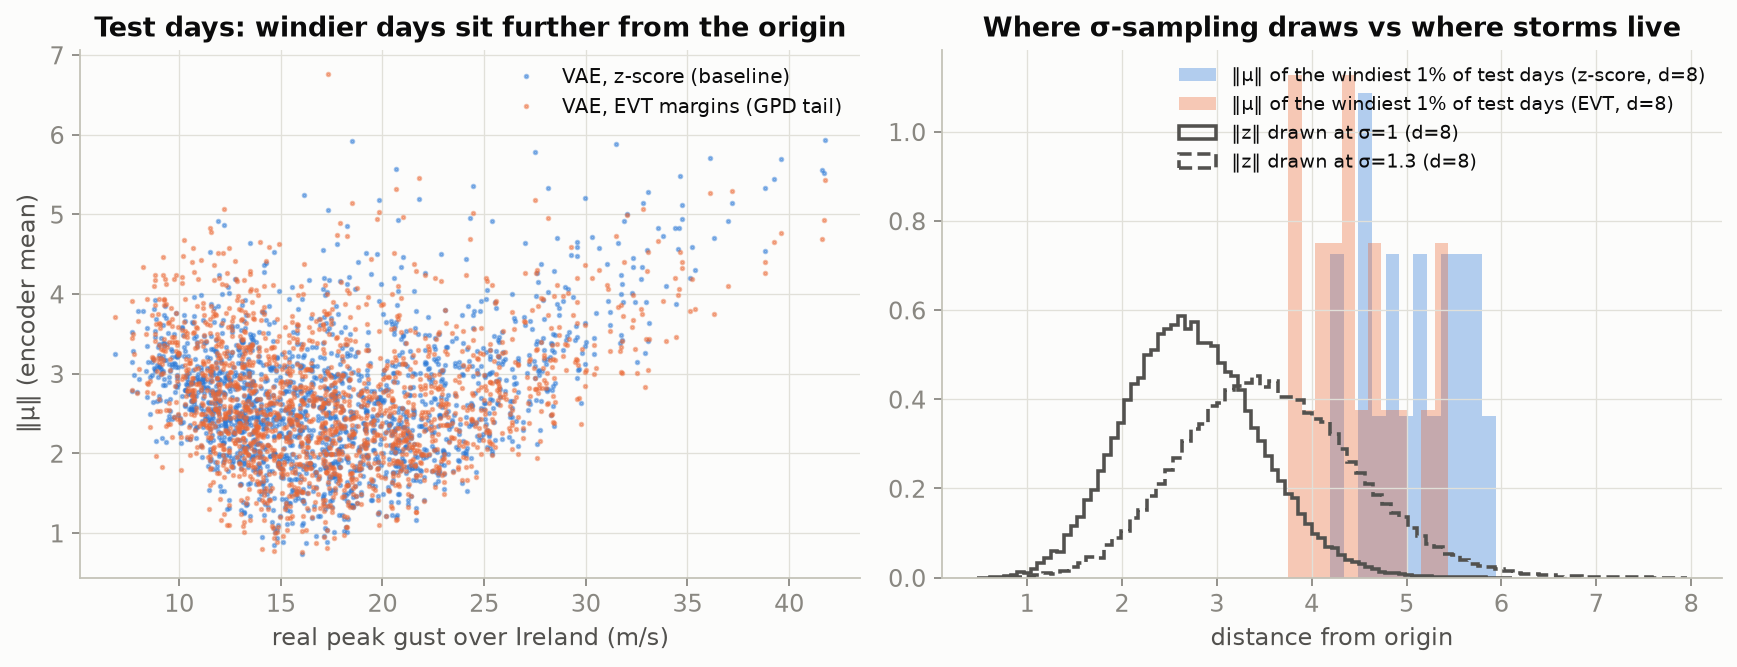

In [6]:
display(Image(str(TALK / "figures" / "08_latent_norms.png")))

**The key number:** under the prior, a code as far out as a typical storm's is a **1-in-1000** draw, yet
storms are **1 in 100** days. At σ = 1 the model samples the storm region of latent space ~10× too rarely,
which is one direct reason why σ = 1 samples underestimate the extremes.

**Read the left panel carefully:** it's a **U**, not a line. *Calm* days are also far from the origin. The
latent space encodes "how unusual is this day", in either direction. Pushing σ up therefore produces more
calm-extreme days as well as more storms: σ-scaling has no notion of *direction*.

> **🤔 Predict first:** If storms sit at radius ~r* and σ = 1 samples sit at ~√d, roughly what σ would put typical samples at the storm radius?
>
> <details><summary>Answer (open after you've guessed)</summary>
>
> σ ≈ r*/√d. That is the 'naive' σ that makes storm-like codes typical. But then *every* sample is storm-like, so the median day is far too windy: σ-scaling moves the whole distribution, not just its tail (Section 5).
>
> </details>

## 5. σ-scaling: what it really does

Sampling $z\sim\mathcal N(0,\sigma^2 I)$ multiplies every latent radius by σ. In terms of probability, a code at
radius $r$ has density $\propto e^{-r^2/(2\sigma^2)}$, so the *relative* frequency of far-out codes rises
sharply. But it is **one knob for the whole distribution**: the median day, the 1-in-100 day and the
1-in-1000 day all move together, at rates set by the decoder. There is no reason the σ that fixes the
1-in-1000 day also leaves the typical day correct, and no reason σ = 1.3 corresponds to any particular return
period. Section 8 measures this.

✍️ **Exercise 5.1.** Using `W.sample(model, tf, n, sigma)`, find (by bisection) the σ for which the generated
99th percentile of the Ireland peak (`W.domain_max(g, mask)`) equals the real one from `train`. Then report the
generated median at that σ. *Hint: 6–8 bisection steps on σ ∈ [1, 2.5] with n = 14610 are enough.*

In [7]:
# ✍️ your code here

## 6. Model (b): extreme-value margins

**Idea.** Give the VAE inputs whose **every pixel is exactly N(0, 1)**, with the mapping to m/s built from
extreme-value theory, so that whatever the VAE generates in the tail is translated back with a *physically
fitted tail* instead of a straight line.

**Step 1: the probability integral transform (PIT).** If $X$ has a continuous CDF $F$, then $U = F(X)$ is uniform
on (0, 1), and $Z = \Phi^{-1}(U)$ is exactly $\mathcal N(0,1)$. Inverse: $x = F^{-1}(\Phi(z))$.

**Step 2: the empirical CDF fails in the tail.** The empirical $F^{-1}$ can only return values already seen: a
generated $z = 5$ would map to the training maximum, never beyond. Useless for extremes.

**Step 3: a GPD tail.** Above a threshold $u$ (here the per-pixel 95th percentile), the
**Pickands–Balkema–de Haan theorem** says excesses $Y = X - u$ approximately follow a Generalised Pareto
distribution, for almost any parent distribution:

$$
P(Y > y \mid X > u) = \Big(1 + \xi\,\frac{y}{\sigma_u}\Big)^{-1/\xi}
$$

$\xi$ (shape) sets the tail type: ξ > 0 heavy (power law), ξ = 0 exponential, ξ < 0 **bounded** with an upper
end point at $u - \sigma_u/\xi$. The full per-pixel CDF stitches the empirical body to the GPD tail:

$$
F(x) = \begin{cases}\hat F_{\text{emp}}(x) & x \le u\\ 1 - (1-0.95)\,\big(1 + \xi (x-u)/\sigma_u\big)^{-1/\xi} & x > u\end{cases}
$$

1024 GPDs are fitted by maximum likelihood (`scipy.stats.genpareto.fit`), one per pixel, on the **training
years only**.

xi: median -0.068, range -0.199 to 0.003; roundtrip error 1.9e-06 m/s


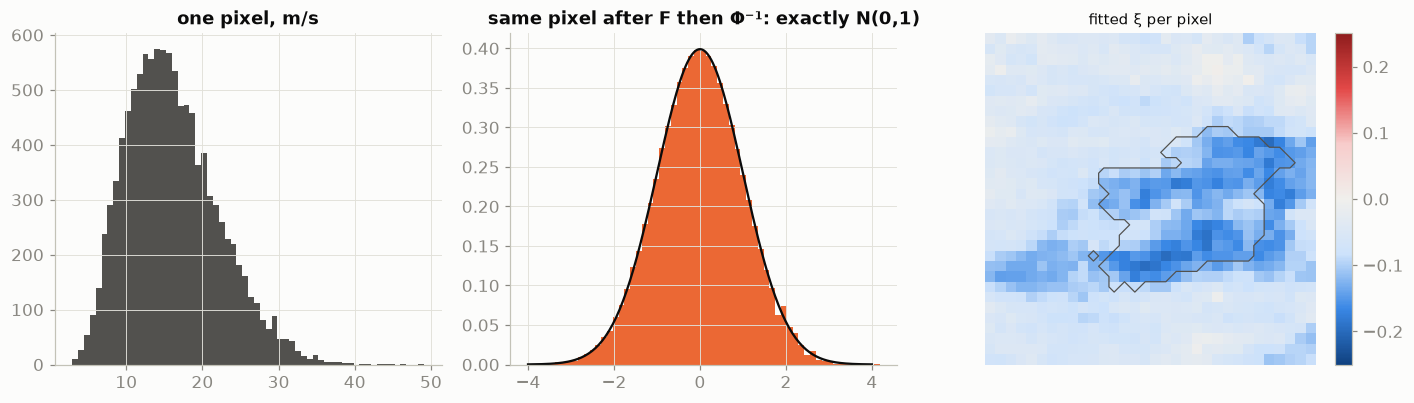

In [8]:
ev = models["evt"][1]
z_train = ev.forward(train)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(train[:, 20, 10], bins=60, color=P.INK2); axes[0].set_title("one pixel, m/s")
axes[1].hist(z_train[:, 20, 10], bins=60, color=P.COLORS["evt"], density=True)
g = np.linspace(-4, 4, 200); axes[1].plot(g, np.exp(-g**2/2)/np.sqrt(2*np.pi), color=P.INK, lw=1.5)
axes[1].set_title("same pixel after F then Φ⁻¹: exactly N(0,1)")
im = P.wind_map(axes[2], ev.xi.reshape(32, 32), lat, lon, vmin=-0.25, vmax=0.25, cmap=P.DIVERGE, mask=mask,
                peak=False, title="fitted ξ per pixel")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
print(f"xi: median {np.median(ev.xi):.3f}, range {ev.xi.min():.3f} to {ev.xi.max():.3f};"
      f" roundtrip error {np.abs(ev.inverse(z_train[:500]) - train[:500]).max():.1e} m/s")

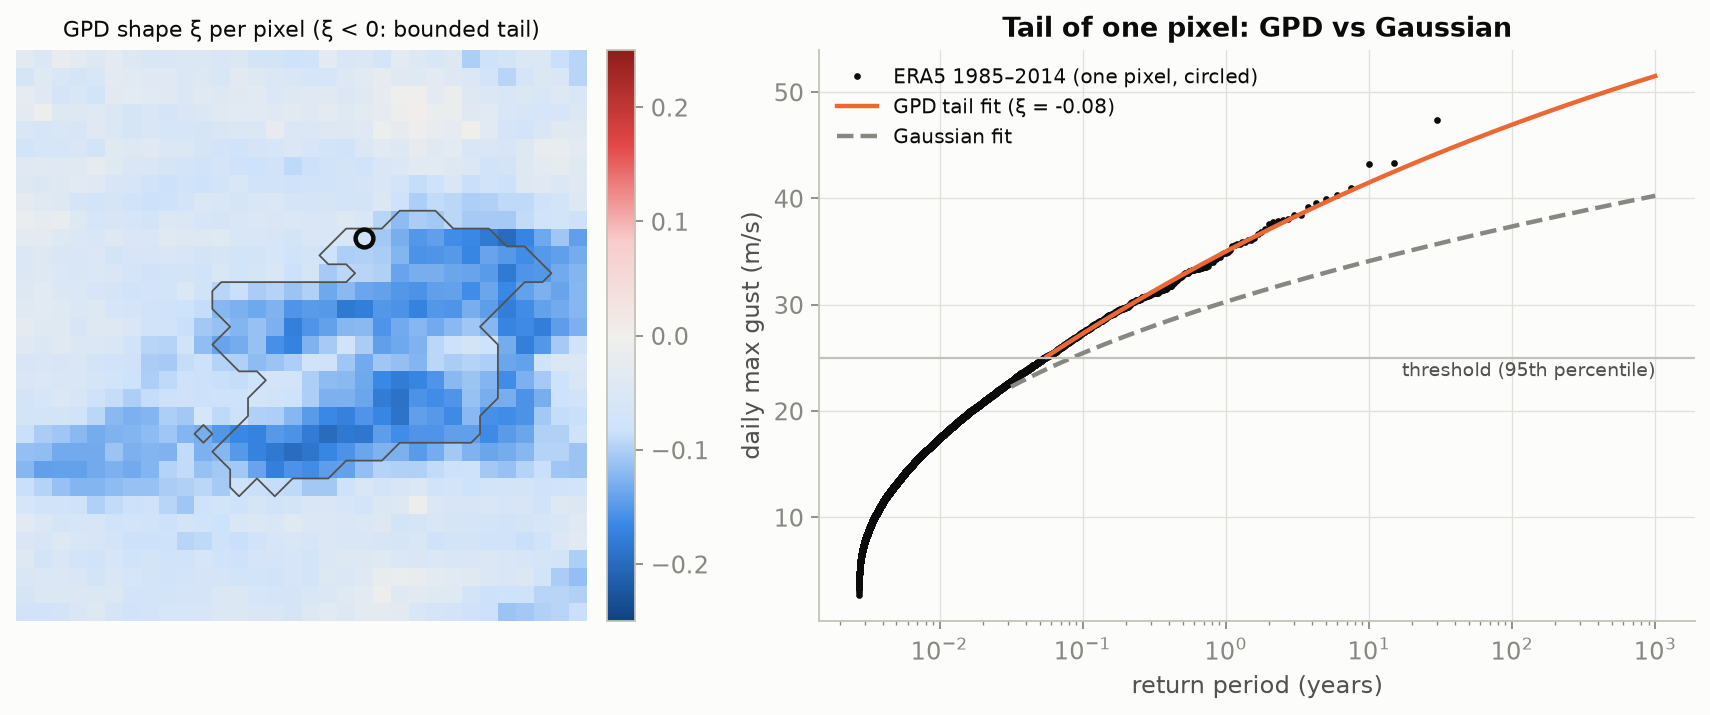

In [9]:
display(Image(str(TALK / "figures" / "02_gpd_fit.png")))

**What's interesting.** ξ is slightly **negative almost everywhere**: daily-max gust has a *bounded* tail (it
can't grow without limit), and more strongly so over land (surface friction caps gusts) than over the open
ocean. The Gaussian fit in the right panel underestimates the tail badly, while the GPD follows the data out to
the 30-year storm.

> **🤔 Predict first:** After the EVT transform, a 1-in-1000-day gust at one pixel sits at z ≈ Φ⁻¹(0.999) ≈ 3.1. Under the z-score it sits at ≈ +4 to +5. Which model's MSE cares *more* about getting storm pixels right?
>
> <details><summary>Answer (open after you've guessed)</summary>
>
> The **z-score** model. The EVT transform compresses the tail (like log1p did, but in a principled way), so a given m/s error on a storm pixel is a *smaller* error in EVT space. The EVT model's advantage is not sharper storms; it is that whatever tail it produces is translated back through a fitted, extrapolating GPD, and that it can never produce impossible values (negative gusts). This trade-off is exactly what Section 8 tests.
>
> </details>

## 7. Tuning: what was optimised, and why the tails were left out

Sweep: latent size $d\in\{8,16,32,64\}$ × β ∈ {0.25, 0.5, 1, 2, 4}, for both models, judged on the
**validation years only**. The selection score is **sample realism in the bulk**: the mean absolute difference
(m/s) between generated (σ = 1) and real validation quantiles from 10% to 90%, for pixel values and for the
daily domain max.

The tails were **deliberately excluded** from the score. If we had tuned on the 99th percentile, the model that
"matches the extremes" would be partly matched by selection, and the extreme comparison would no longer be a
test. Picking on the bulk and then *looking at* the tails keeps the hypothesis falsifiable.

Chosen: z-score VAE d = 8, β = 1; EVT VAE
d = 8, β = 1. Each was then retrained with 3 seeds.

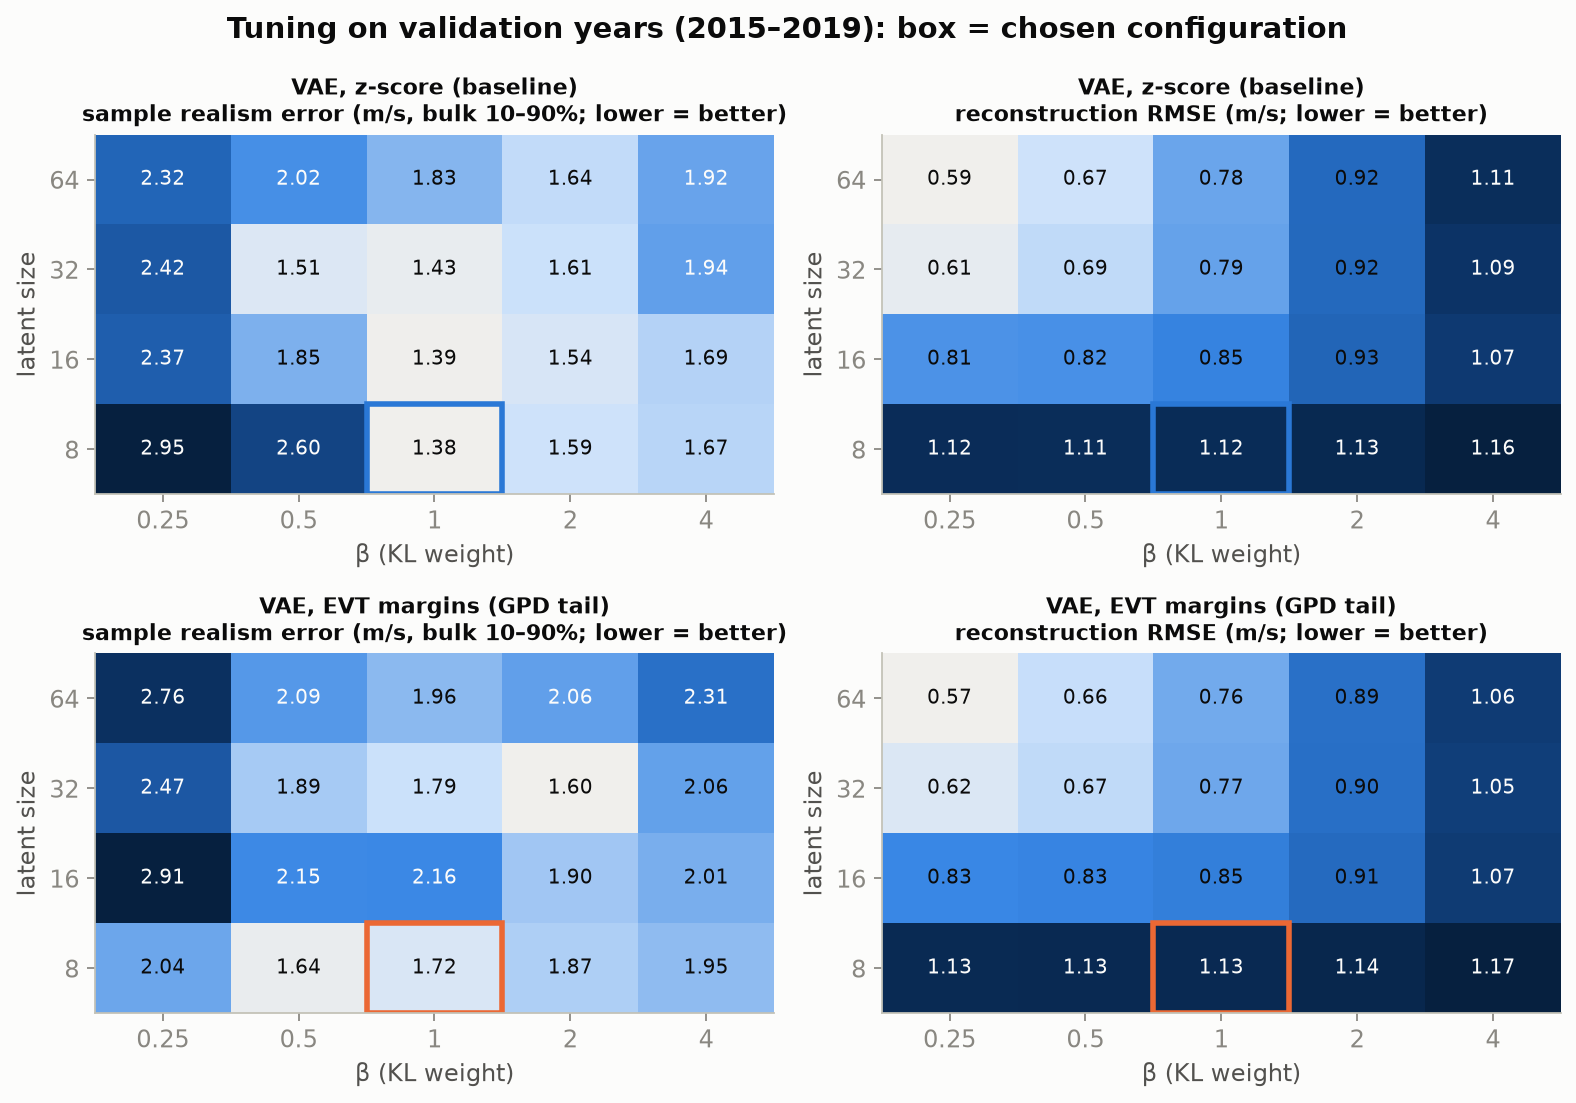

,transform,latent_dim,beta,val_rmse_ms,bulk_score,active_dims,gen_dmax_q99,real_dmax_q99
2,zscore,8,1.0,1.118000,1.378985,8,33.618774,39.079998
7,zscore,16,1.0,0.847677,1.389175,16,33.377953,39.079998
12,zscore,32,1.0,0.788827,1.429459,21,33.273972,39.079998
33,evt,32,2.0,0.895737,1.600485,18,34.621059,39.079998
21,evt,8,0.5,1.131509,1.640004,8,32.796829,39.079998
22,evt,8,1.0,1.131813,1.721563,8,33.604687,39.079998


In [10]:
tun = pd.read_csv(TALK / "results" / "tuning.csv")
display(Image(str(TALK / "figures" / "01_tuning.png")))
tun.sort_values("bulk_score").groupby("transform").head(3)[["transform", "latent_dim", "beta", "val_rmse_ms", "bulk_score", "active_dims", "gen_dmax_q99", "real_dmax_q99"]]

**Reading the landscape.**
- **Reconstruction improves with latent size** (1.12 → 0.59 m/s from d = 8 to 64 at small β): more dimensions,
  more detail stored per day.
- **Sample realism does not.** For every size it is best near **β = 1**: smaller β leaves holes in the latent
  space that random codes fall into; larger β blurs everything. At large d, many dimensions switch off
  ("active dims" in the table: e.g. 20/64 at β = 1). The KL cost of using them isn't worth it.
- **Seed noise is real.** Retraining the top candidates with 2 more seeds (`results/seed_noise.csv`) gives a
  spread of 0.02–0.3 m/s in the score, as big as many of the differences in the heat map. Single-seed rankings
  of near-ties are partly luck.
- **One shared configuration** (d = 8, β = 1, the best summed score over both models, and still best when
  averaged over 3 seeds) so that any difference between the two models comes from the *transform*, not the
  architecture. A sensitivity check at d = 32 is in Section 8.3.

> **🤔 Predict first:** Why does reconstruction error fall with latent size while sample realism does not keep improving?
>
> <details><summary>Answer (open after you've guessed)</summary>
>
> A bigger latent space can store more detail about each day (better reconstructions), but the KL term then has more dimensions to keep close to N(0, I). Codes of real days can end up in regions the prior rarely samples ('holes'), so decoded *random* codes look less like real days. Reconstruction and generation are different goals; β trades them off.
>
> </details>

## 8. Results on the test years (2020–2024)

### 8.1 Reconstructions: the peaks are flattened

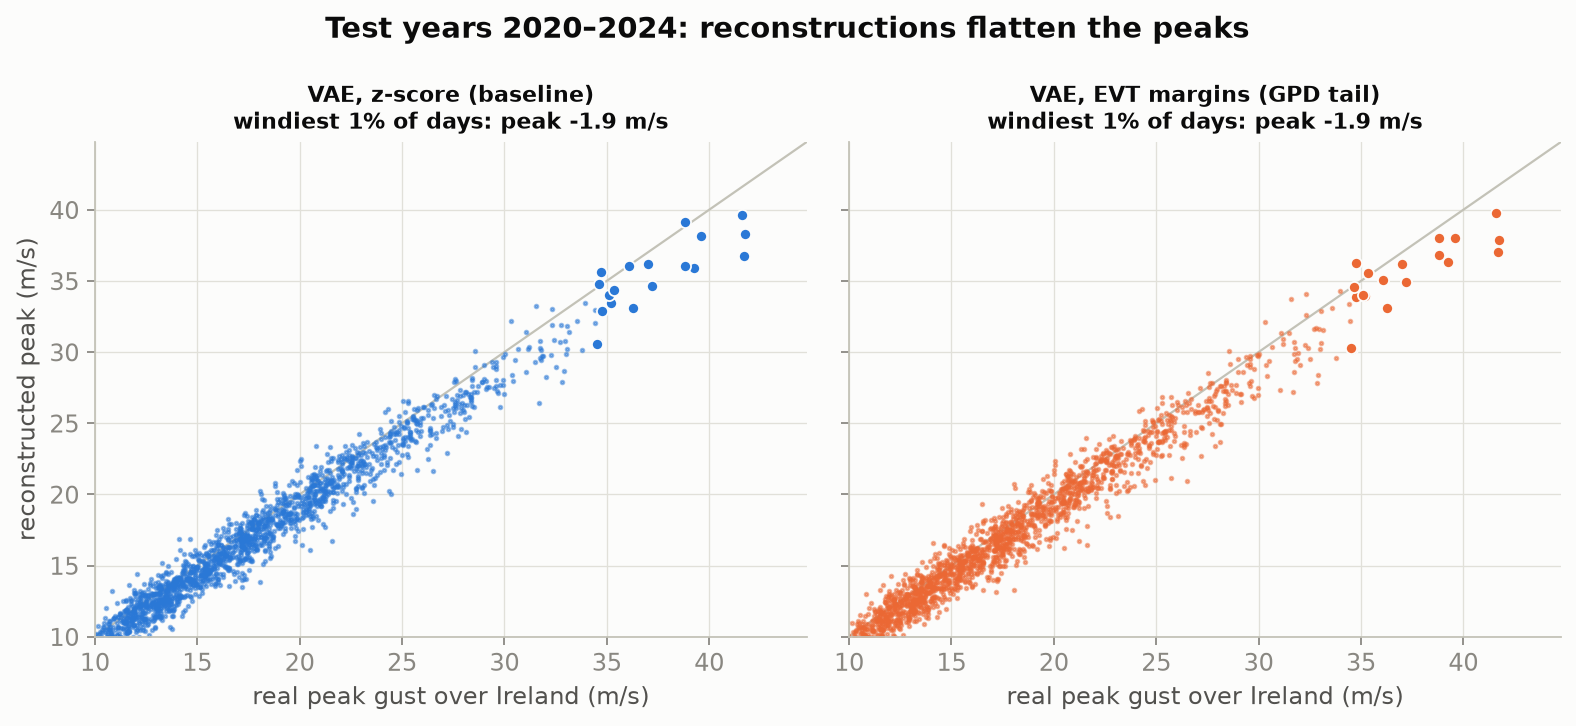

rmse_ms      rmse_ireland_ms      peak_bias_all_ms        \
          mean  std            mean  std             mean   std   
model                                                             
evt       1.14  0.0            1.02  0.0            -0.71  0.03   
zscore    1.13  0.0            1.06  0.0            -0.77  0.04   

       peak_bias_top1pct_ms        
                       mean   std  
model                              
evt                   -1.80  0.08  
zscore                -1.69  0.23

In [11]:
display(Image(str(TALK / "figures" / "03_reconstruction_peaks.png")))
pd.read_csv(TALK / "results" / "reconstruction_test.csv").groupby("model").agg(["mean", "std"]).drop(columns="seed").round(2)

- Both reconstruct with ≈ **1.1 m/s** RMSE per pixel on the test years; on the **windiest 1% of days the
  peak over Ireland comes out ≈ 1.7–1.8 m/s too low** in both models (3 seeds).
- **The transform does not fix the blur**, exactly as Section 3 predicted: the peak bias is a property of the
  MSE loss and the bottleneck, not of the input scale. (The EVT model's MSE even weights storm pixels *less*,
  Section 6, yet its peak bias is the same: the bottleneck, d = 8, dominates.)

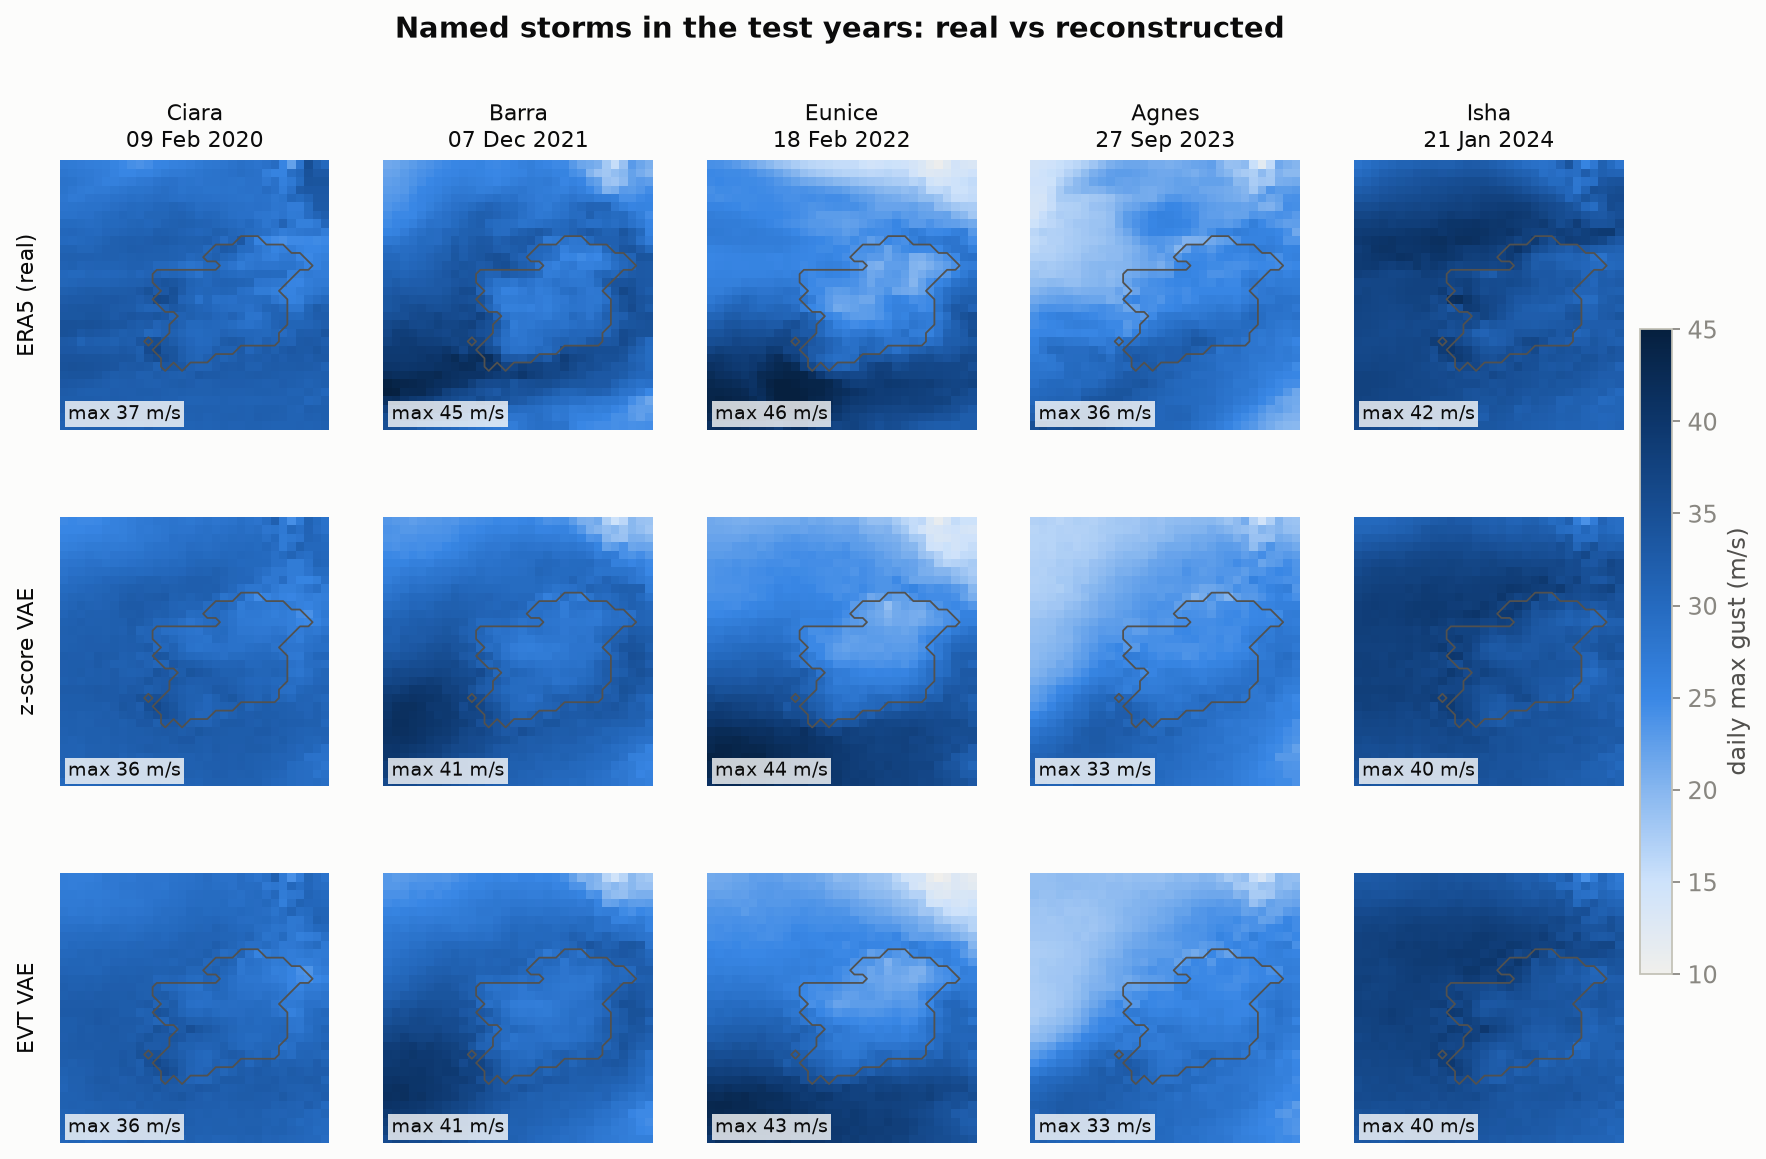

In [12]:
display(Image(str(TALK / "figures" / "04_storms.png")))

Both models keep each storm's **footprint**: where the strongest band sits (Barra and Eunice in the south,
Isha in the north-west). They lose the sharpest detail. The worst case is **Barra: 41.7 m/s real over Ireland →
36.7 (z-score) / 37.0 (EVT)**; Isha 41.6 → 39.6 / 39.8; Ciara and Eunice are within 1 m/s.

### 8.2 Generation: return levels

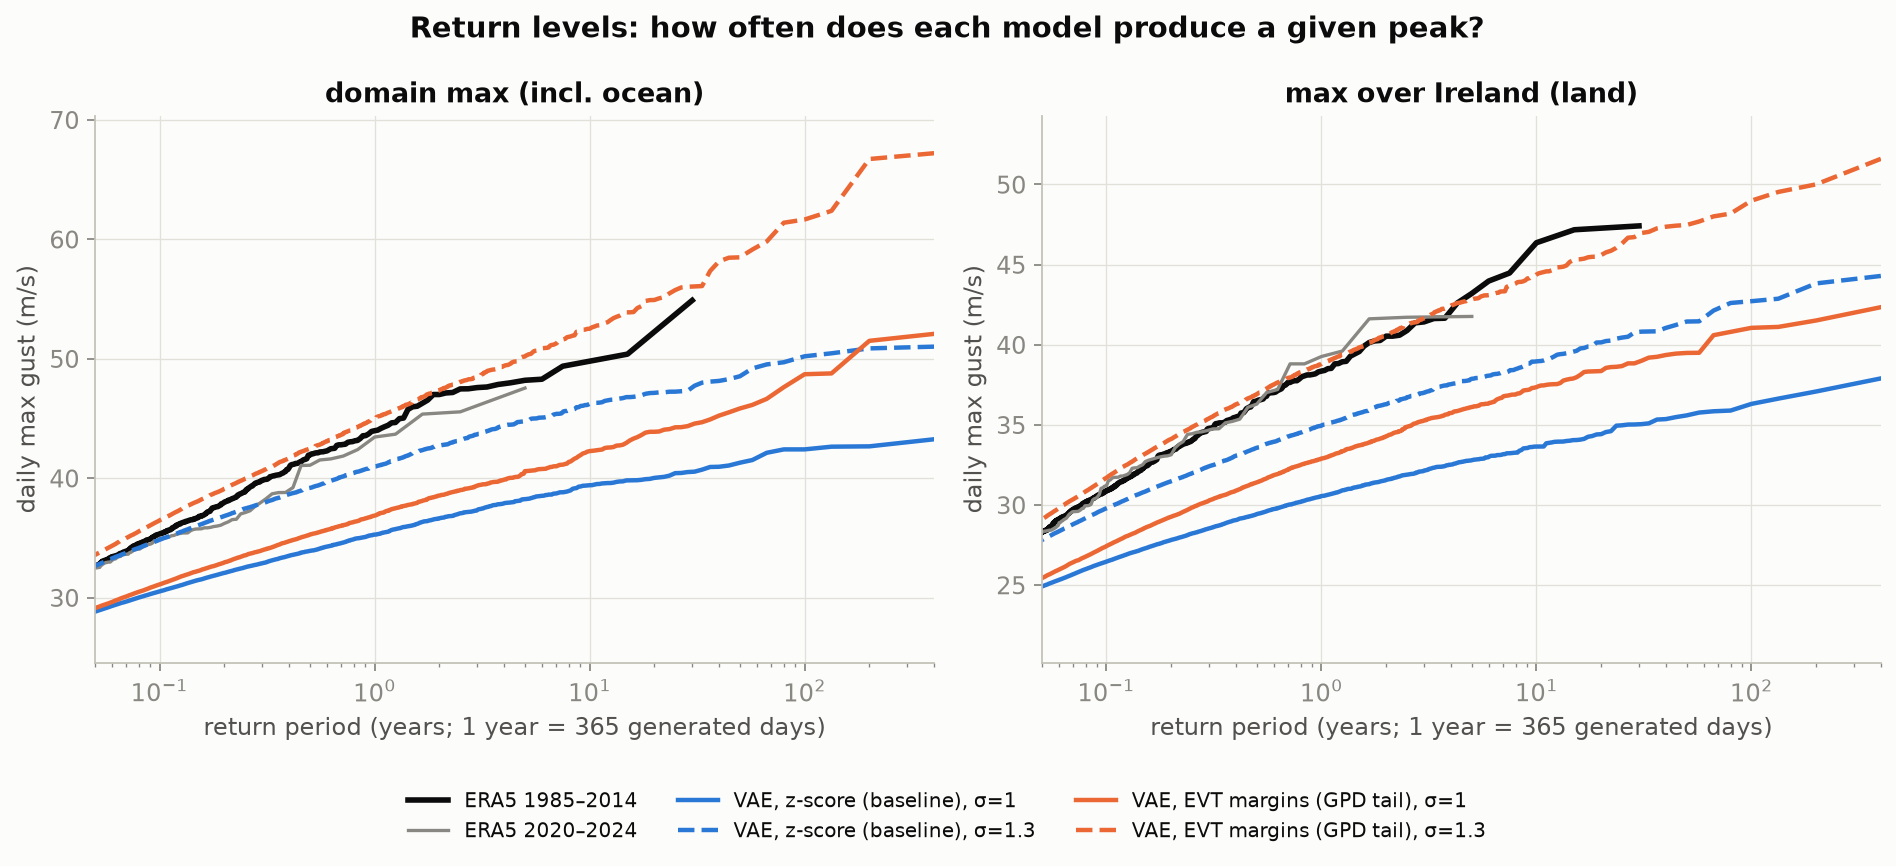

In [13]:
display(Image(str(TALK / "figures" / "05_return_levels.png")))

This is the main result. **Over Ireland (right panel):**
- **σ = 1 (solid):** both models sit **4–6 m/s below ERA5 at every return period**. The hypothesis holds: the
  standard VAE underestimates extremes. (1-in-100-day gust: real 34.4, z-score 28.5, EVT 29.3 m/s.)
- **σ = 1.3 (dashed):** the **EVT model tracks the ERA5 curve** out to ≈ 10-year return periods and
  extrapolates smoothly beyond (51.6 m/s in 400 generated years vs 47.4 m/s in the 30-year record). The
  **z-score model is still ≈ 3–4 m/s low** at σ = 1.3.

**Over the whole box (left panel)** the EVT model at σ = 1.3 *overshoots* beyond ≈ 2-year return periods (up to
67 m/s). Its GPD tails over the open ocean have ξ ≈ 0, so they barely bound the extrapolation (median fitted
upper end point 76 m/s over the ocean vs 47 m/s over Ireland). A calibrated tail is only as good as its ξ.

### 8.3 σ-scaling: one knob for the whole distribution

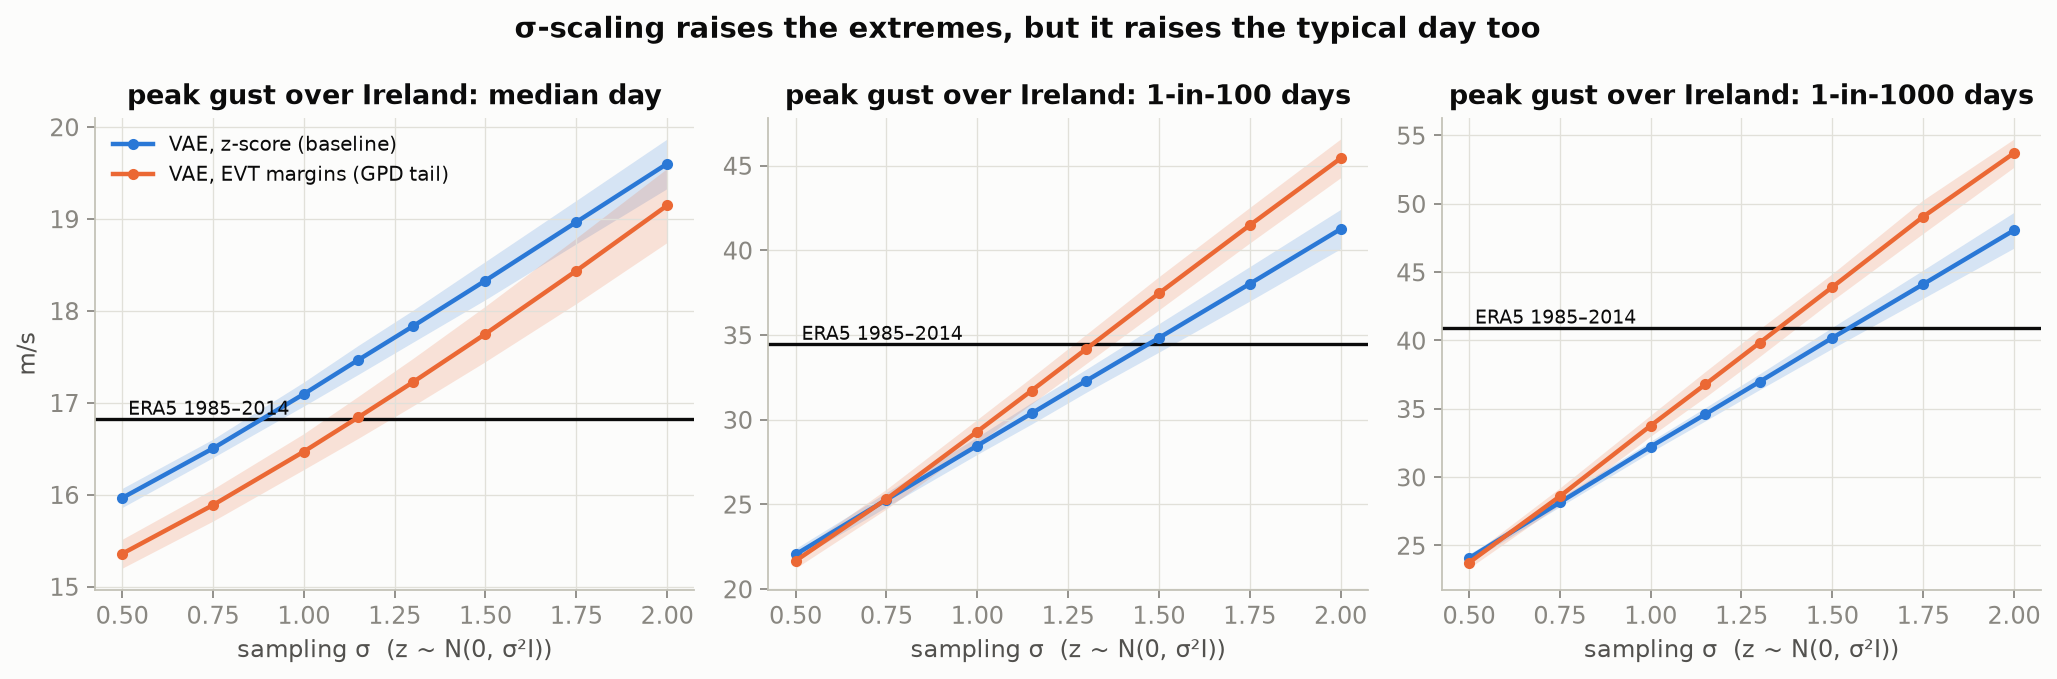

,source,sigma,ireland_q50_mean,ireland_q99_mean,ireland_q99.9_mean,ireland_max_mean,pct_maps_negative_mean,pct_maps_above_train_max_mean
0,ERA5 test 2020–2024,NaN,16.8,34.5,41.6,41.8,0.0,0.0
1,ERA5 train 1985–2014,NaN,16.8,34.4,40.9,47.4,0.0,0.0
2,evt,0.5,15.4,21.7,23.7,26.2,0.0,0.0
3,evt,0.8,15.9,25.3,28.6,32.6,0.0,0.0
4,evt,1.0,16.5,29.3,33.8,38.9,0.0,0.0
5,evt,1.2,16.8,31.7,36.8,42.8,0.0,0.0
6,evt,1.3,17.2,34.2,39.8,46.6,0.0,0.0
7,evt,1.5,17.8,37.4,43.9,51.4,0.0,0.1
8,evt,1.8,18.4,41.5,49.0,57.8,0.0,0.5
9,evt,2.0,19.2,45.4,53.7,64.1,0.0,1.5


In [14]:
display(Image(str(TALK / "figures" / "06_sigma_quantiles.png")))
tab = pd.read_csv(TALK / "results" / "tail_table.csv")
cols = ["source", "sigma", "ireland_q50_mean", "ireland_q99_mean", "ireland_q99.9_mean", "ireland_max_mean",
        "pct_maps_negative_mean", "pct_maps_above_train_max_mean"]
tab[cols].round(1)

In [15]:
pd.DataFrame(summary["matched_sigma"]).T

,sigma,median_at_sigma,real_median
zscore_ireland_q99,1.470,18.25,16.82
zscore_ireland_q99.9,1.546,18.45,16.82
evt_ireland_q99,1.316,17.27,16.82
evt_ireland_q99.9,1.353,17.36,16.82


- **One knob moves everything.** To match the real 1-in-100-day gust over Ireland, the z-score model needs
  **σ ≈ 1.47**, and at that σ its **median day is 18.3 m/s instead of 16.8 (+1.4 m/s too windy)**. The EVT
  model needs only **σ ≈ 1.32**, with a median of 17.3 (**+0.45 m/s**).
- **Impossible weather.** The z-score model generates **negative gusts**: 0.2% of maps at σ = 1, 2.3% at
  σ = 1.3, 6.3% at σ = 1.5, 21% at σ = 2. Its inverse transform is a straight line, so nothing stops a decoded
  value going below zero. The EVT model **never** does (its CDF starts at 0 m/s).
- **Sensitivity (d = 32, one seed; `results/sensitivity_d32.log`):** same direction, smaller gap. Matched σ
  1.35 (z-score) vs 1.32 (EVT); median +0.9 vs +0.4 m/s; z-score negative gusts in 2.8% of maps at σ = 1.3,
  EVT 0%. **Robust:** both underestimate at σ = 1; EVT needs less σ, distorts the typical day less, never
  produces negative gusts. **Not robust:** the size of the gap.

### 8.4 What do the most extreme generated maps look like?

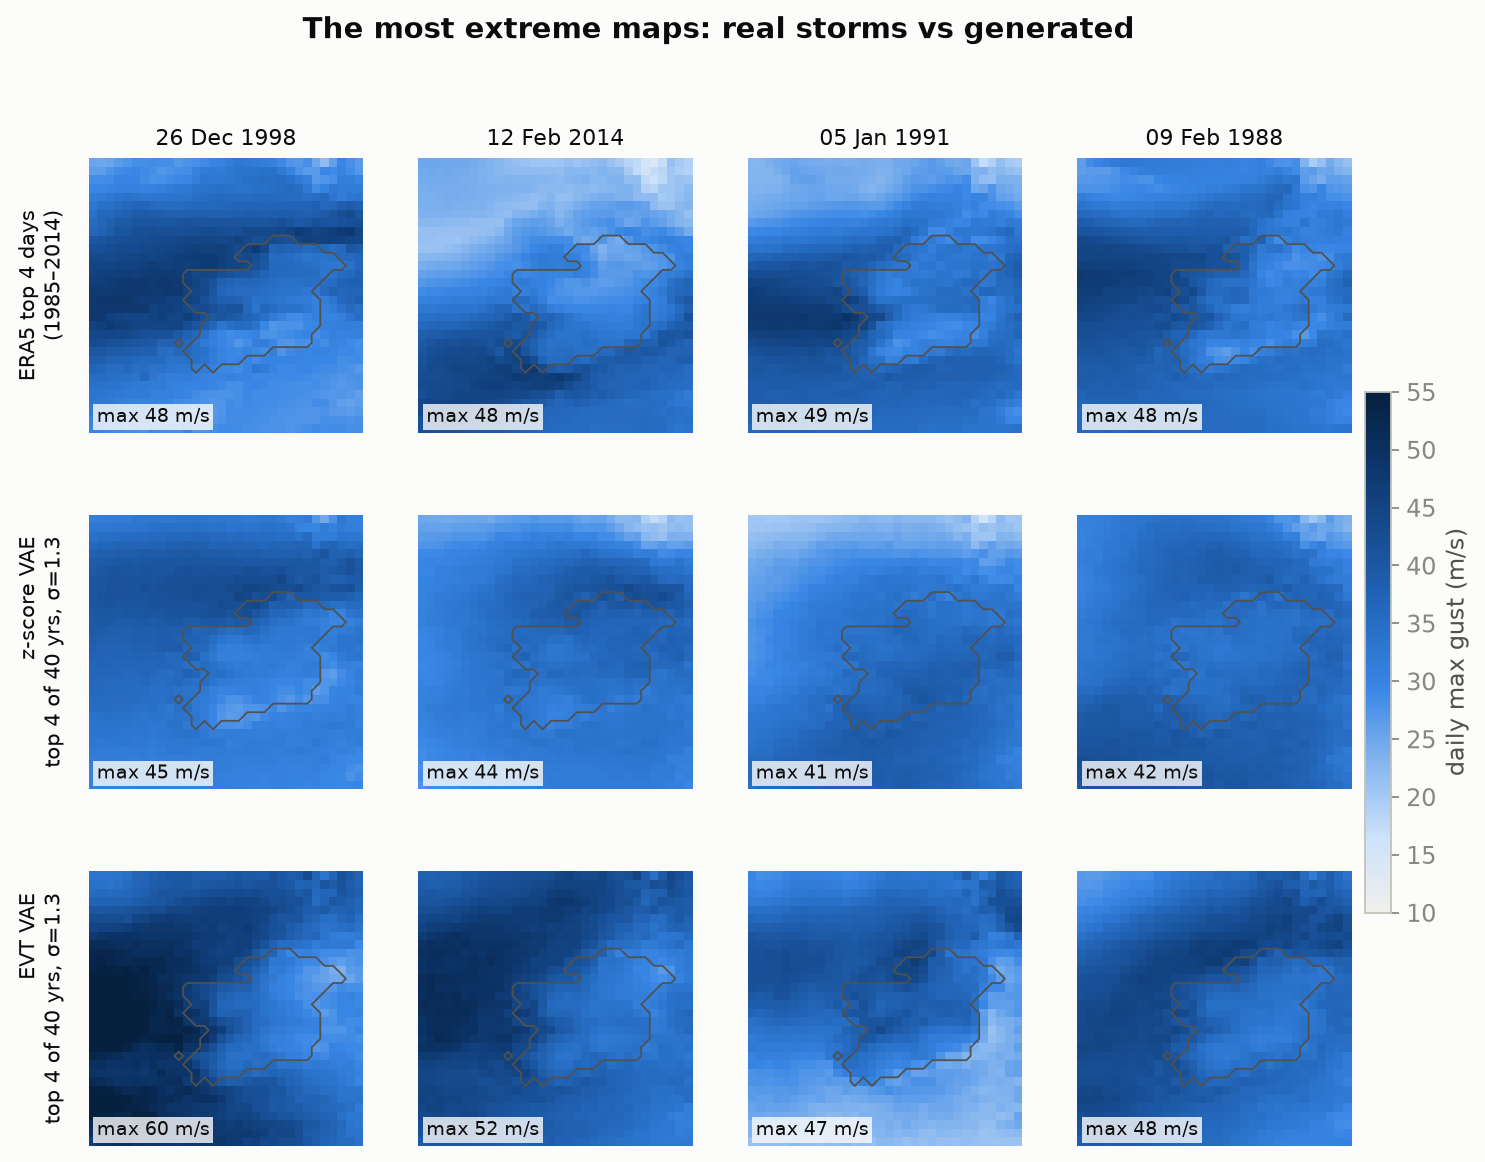

In [16]:
display(Image(str(TALK / "figures" / "07_extreme_samples.png")))

Top row: the four windiest real days in 30 years (48–49 m/s). Rows 2–3: the four most extreme of **40 years**
of generated days at σ = 1.3. The **z-score model's most extreme maps (41–45 m/s) are still weaker than the
real top 4**, even with σ-scaling and more years. The EVT model's reach 47–60 m/s, with the strongest winds in
the west/north-west as in real storms, but its footprints are **broader and smoother**: real storms have
sharp, narrow bands. That's the MSE blur again (Section 3), now in generation. So: marginally right, spatially
too smooth.

### 8.5 Where in space does each model fall short?

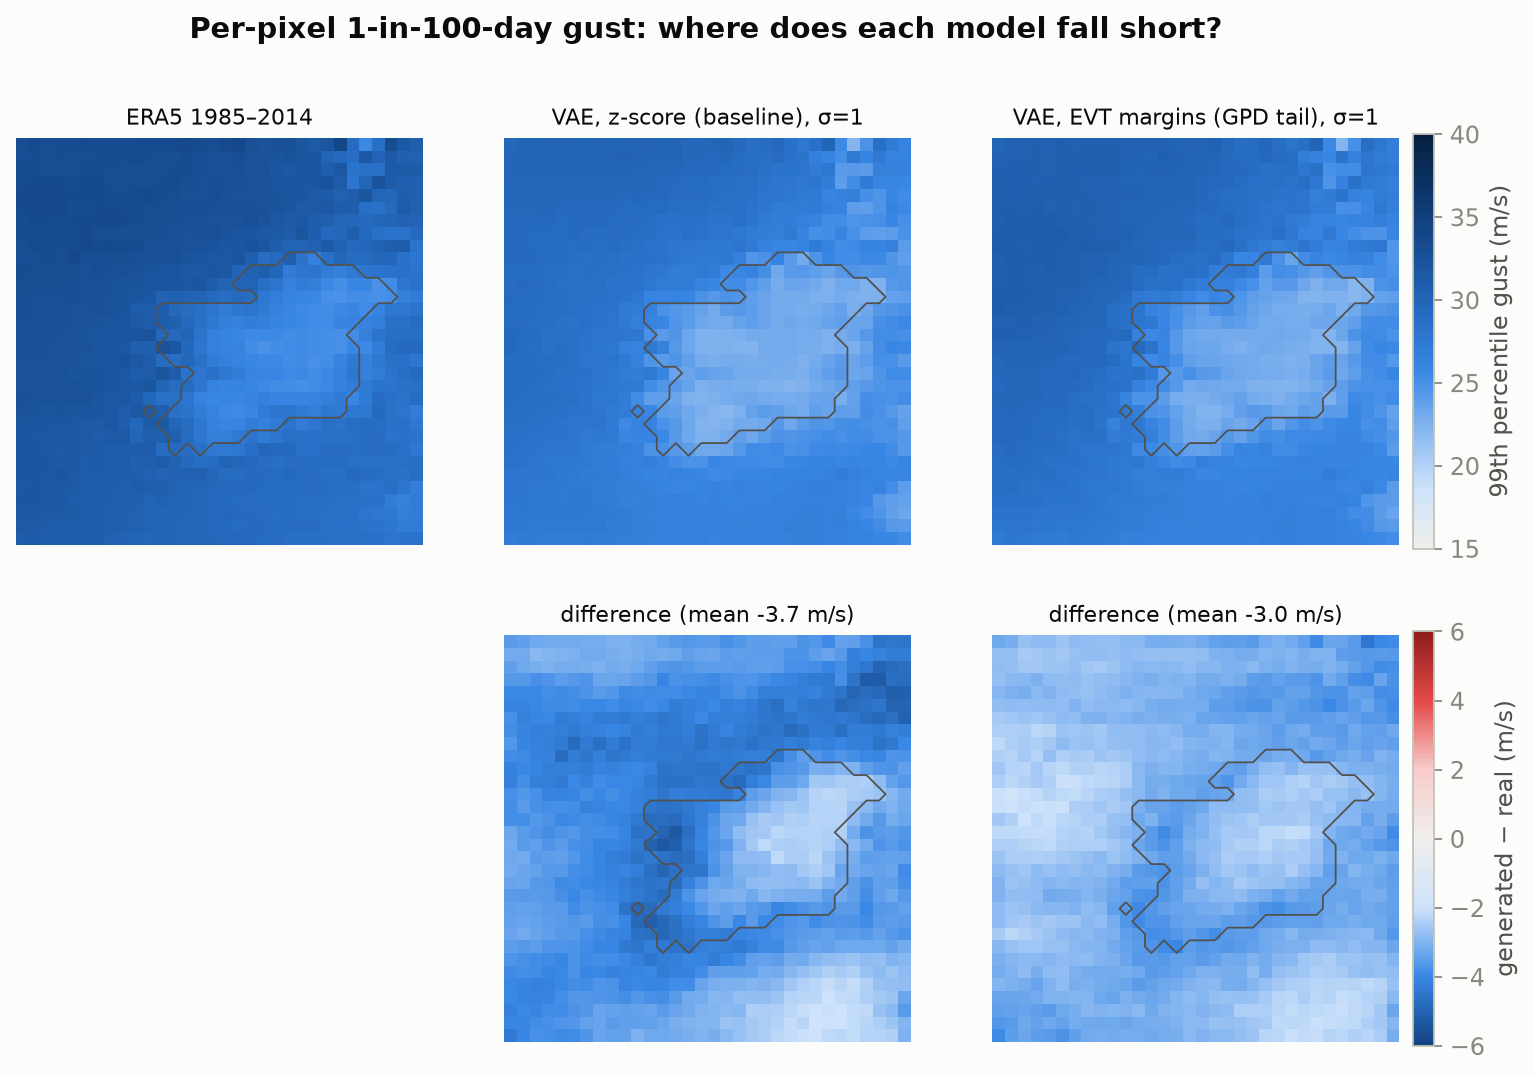

In [17]:
display(Image(str(TALK / "figures" / "09_q99_maps.png")))

At σ = 1 both models undershoot the 1-in-100-day gust everywhere (mean −3.7 m/s z-score, −3.0 m/s EVT).
The **z-score deficit is concentrated along Ireland's west coast and the Atlantic margin (−5 to −6 m/s)**, which
is where the most damaging storms arrive. The EVT deficit is more uniform. A single global mean/std can't
represent that the coast has a different tail from the inland.

### 8.6 Play: sample at any σ
Change `SIGMA` and `MODEL` and re-run. Same colour scale as the real days on the left.

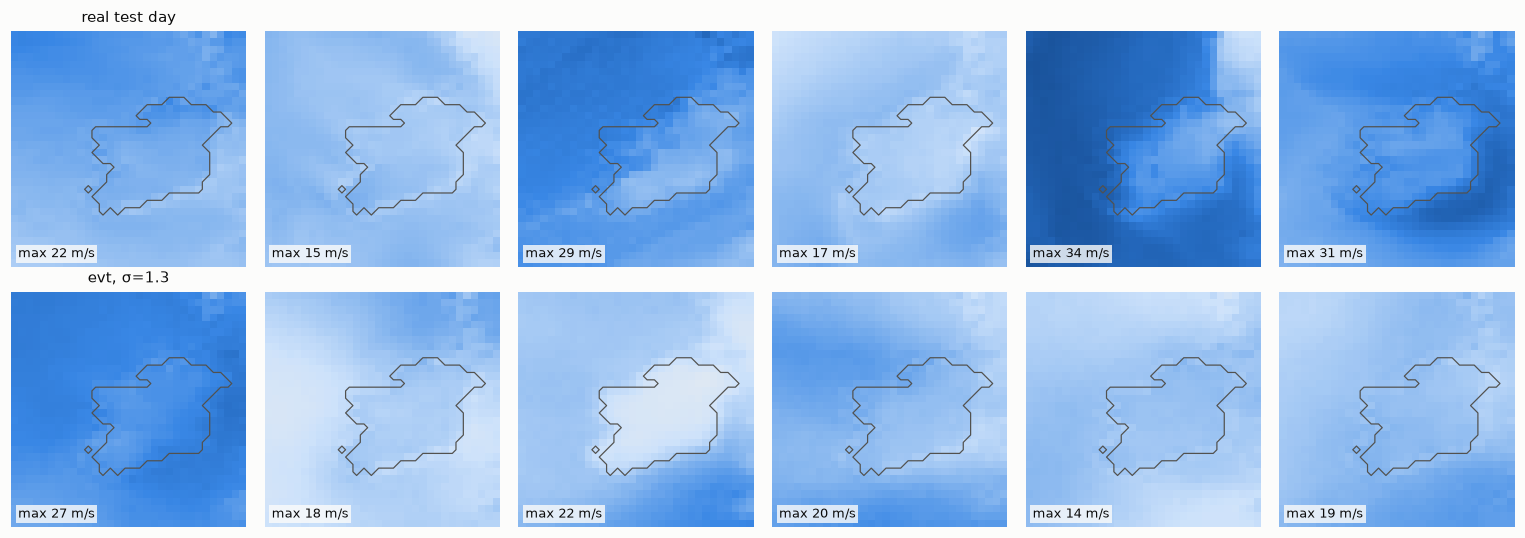

In [18]:
SIGMA, MODEL = 1.3, "evt"          # try 0.5, 1, 1.6, 2.5; "zscore" or "evt"
m, tf = models[MODEL][:2]
g = W.sample(m, tf, 6, SIGMA, seed=np.random.randint(1e6))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
idx = np.random.choice(len(test), 6, replace=False)
for j in range(6):
    P.wind_map(axes[0, j], test[idx[j]], lat, lon, vmin=0, vmax=50, mask=mask, title="real test day" if j == 0 else None)
    P.wind_map(axes[1, j], g[j], lat, lon, vmin=0, vmax=50, mask=mask, title=f"{MODEL}, σ={SIGMA}" if j == 0 else None)
plt.tight_layout()

## 9. Visualisation choices (and why)

| Choice | Why |
|---|---|
| **Return-level plots** (log return period on x) instead of histograms | The tail is <1% of the data; a histogram puts it in invisible bars. A log x-axis gives each decade of rarity equal space. |
| **Ireland land max** as well as domain max | The strongest gusts in the box are over the NW ocean. Impacts (damage, grid, insurance) are on land, and the land tail is shaped by surface friction (ξ more negative). |
| **One shared colour scale per figure**, starting at 10 m/s | Peaks are only comparable on the same scale; starting at 0 wastes half the colour range on calm values nobody looks at in a storm. |
| **Single-hue sequential map colours** (light → dark blue), **blue↔grey↔red** for differences | Magnitude is ordered, so one hue whose darkness increases reads correctly; a rainbow invents boundaries. Differences have a sign, so two hues with a neutral zero. |
| **Fixed colours per model** (blue = z-score, orange = EVT; black = real) | The same colour means the same thing in every figure. Blue/orange is colour-blind safe (validated: ΔE ≈ 25 under protanopia). |
| **Line style for σ** (solid σ = 1, dashed σ = 1.3) | σ is a second variable; giving it its own channel keeps colour = model everywhere. |
| **Bands = ± 1 s.d. over 3 seeds** | A difference smaller than the seed-to-seed spread is not a result. |
| **Test-year figures only after tuning was frozen** | Section 7. |

## 10. Limitations (say these in the talk before someone else does)

- **ERA5 underestimates peak gusts** (~25% vs station observations): both "real" and generated extremes are
  ERA5-world extremes.
- **Independence.** GPD fits assume independent exceedances, but stormy days cluster. Declustering (e.g. runs
  method) would widen the uncertainty, mostly not shift ξ.
- **Return periods of generated days** treat each generated day as independent: "1-in-10-years" means
  "1 in 3650 generated days".
- **5 test years** contain only a handful of strong storms: test-year tails are noisy (grey curve).
- **σ is not a calibrated return period.** There is no mapping from σ to "how rare". The EVT margins give
  calibrated *marginal* tails at σ = 1; σ > 1 is still an uncalibrated knob on top.
- **Spatial dependence of extremes.** The EVT transform fixes each pixel's distribution, not how storm pixels
  co-occur. That is the VAE's job, and blurring (Section 3) hurts it.

## 11. Exercises for you (your own `people/james/` code is the place for these)

1. ✍️ **Check the KL formula by Monte Carlo.** For μ = 1.5, σ = 0.5, draw 10⁶ samples from N(μ, σ²) and average
   $\log q(z) - \log p(z)$. Compare with the closed form in Section 2. *Hint: `torch.distributions.Normal(...).log_prob`.*
2. ✍️ **Threshold sensitivity.** Refit `W.EVTMargins(q=0.90)` and `q=0.98`. Does the median ξ change? Why might a
   higher threshold give noisier ξ? (Bias-variance: fewer exceedances vs a better GPD approximation.)
3. ✍️ **Exercise 5.1** above (the matched σ).
4. ✍️ **Learned variance.** In your own `model.py`, make the decoder output a second channel $\log s^2$ per pixel and
   replace the MSE with the Gaussian NLL $\tfrac12\big[(x-\hat x)^2/s^2 + \log s^2\big]$. Prediction: do the
   reconstructed peaks get closer to the real ones? (This attacks the MSE blur directly: Section 3.)
5. ✍️ **Which day is the most "extreme" in latent space?** Find the test day with the largest ‖μ‖. Is it a storm or
   a calm day? (Section 4's U-shape.)